# 03 XGBoost baseline

**The question.** Can a machine-learning model price a single bid item more closely than the simplest yardstick, the median of the item's low bids over the past 12 months?

**What we did.** We fixed the test first: models learn from low bids opened **before 1 January 2024** and are tested on the **4,507 low-bid prices from January 2024 to November 2026**, never a random split, because an estimator only ever knows the past. The score is the *median miss*: half of the predictions miss the low bidder's unit price by less than this. We also report how often a prediction lands within 15%.

We then trained two widely used decision-tree models, **XGBoost** and **LightGBM**. They see only what is known before bids open: the item, its quantity, the place, the date, the contract's size and type of work, and the item's recent median price. Settings were tuned on 2023 bids only, and each final model averages three fits with different random seeds because one fit's score moved by about two points from seed to seed.

**What we found.**
- The historical median misses by **55.0%**. XGBoost cuts that to **46.1%**, LightGBM to **43.4%**. Within 15%: 15.3%, 18.0% and 19.4%.
- The models lean on the item code, the item's recent median price and the quantity. The engineer's estimate (contract size) carries only about **1%** of what they learn.
- **Where they lose:** the plain median beats both models on electrical and signals, bridge rehabilitation, piling and the small "Other" group.
- Both models get worse each year after training (XGBoost 41.3% in 2024, 59.6% in 2026). Notebook 04 shows why, and notebook 05 shows the fix.

The full reports: [`outputs/08_target_split_metrics/`](../outputs/08_target_split_metrics/README.md) (the test) and [`outputs/10_baselines/`](../outputs/10_baselines/README.md) (the models).

## Setup

This loads the project's own code (`src/bidlens/analysis/stages.py`), which reads the results each stage already saved in `outputs/`. Nothing is recomputed here, so the notebook runs in seconds on a fresh copy of the repository, with no database and no model downloads.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root

import matplotlib.pyplot as plt
import pandas as pd

from bidlens.analysis import stages as s

pd.set_option("display.max_colwidth", 140)
plt.rcParams["figure.max_open_warning"] = 0

## The test set

Models learn from the training rows and are scored on the test rows. Contracts where the two Caltrans sources disagree on who bid low are left out of the test, as is any price of $0 or less. Flagged unusual prices stay in, and every score is also reported without them.

In [2]:
s.split_summary()

,Set,Prices,Contracts
0,"Low-bid prices, train (before cutoff)",10296,599
1,"Low-bid prices, test period",4563,242
2,Test prices after exclusions,4507,238
3,of which flagged price outliers,58,45
4,Test contracts with an engineer's estimate and item lines,<NA>,201
5,Headline contracts (90%+ lines with item-level history),<NA>,178


## Overall: how far off is a single item price?

Single items miss by a lot, even for the best method. That is mostly the nature of low bids, not a flaw of the models: notebook 04 shows that a second real bidder differs from the low bidder by 27.5% on the same line.

In [3]:
s.baseline_overall()

,Method,Median miss,Within 15% of the low bid,Median miss without flagged outliers
0,Historical median,55.0%,15.3%,54.0%
1,XGBoost,46.1%,18.0%,45.7%
2,LightGBM,43.4%,19.4%,43.0%


## By item family

Each group of bars is one item family, largest first, with its number of test prices in brackets. Shorter is better. Both models beat the median on most families, with the biggest gains on striping, asphalt, earthwork and minor concrete. On electrical and signals, bridge rehabilitation and piling, the plain median is as good or better.

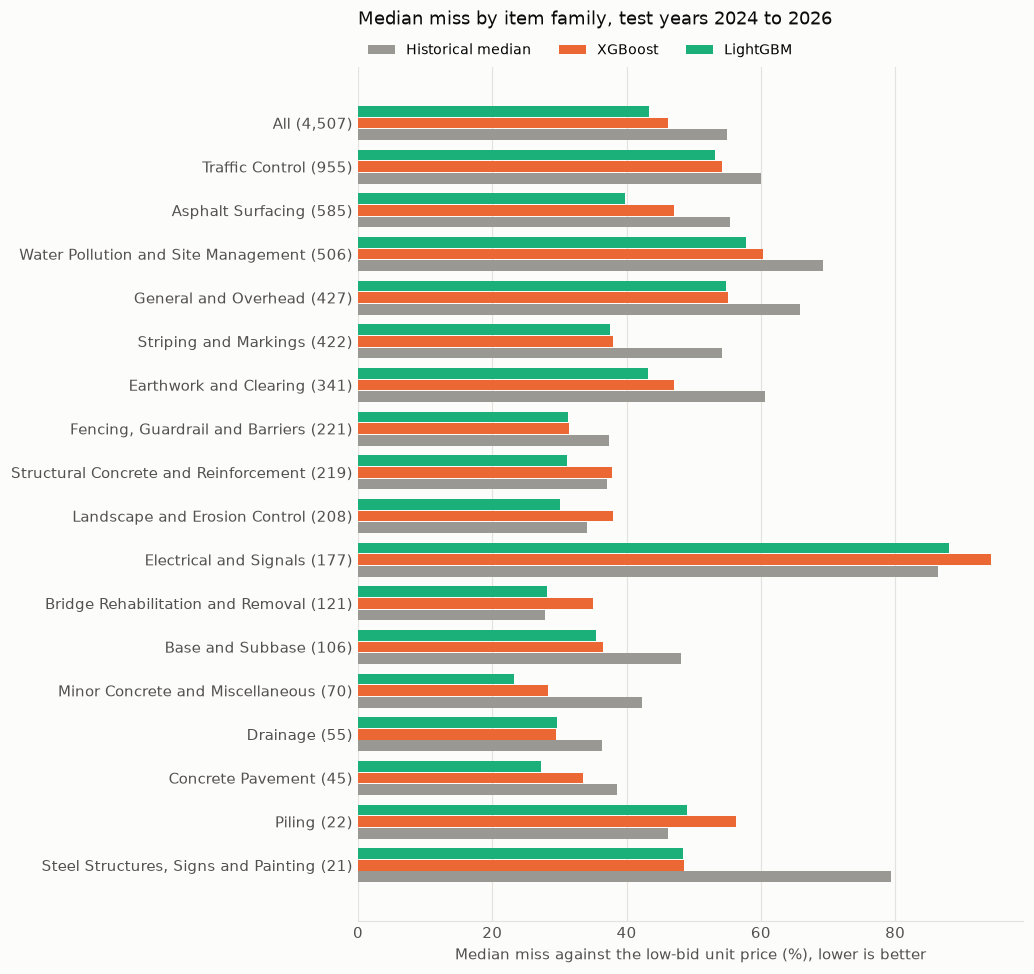

In [4]:
scores = s.baseline_scores()
fam = s.family_table(scores, ["trailing_median", "xgboost", "lightgbm"])
fig = s.chart_family_mdape(
    fam,
    ["trailing_median", "xgboost", "lightgbm"],
    "Median miss by item family, test years 2024 to 2026",
)
s.save(fig, "mdape_by_family", s.S10)
plt.show()

## By bid year

The models were frozen at the end of 2023. The further the test year is from training, the worse they do, while the median, which always uses the latest 12 months, stays about the same. This is the first sign of the drift that notebook 04 measures.

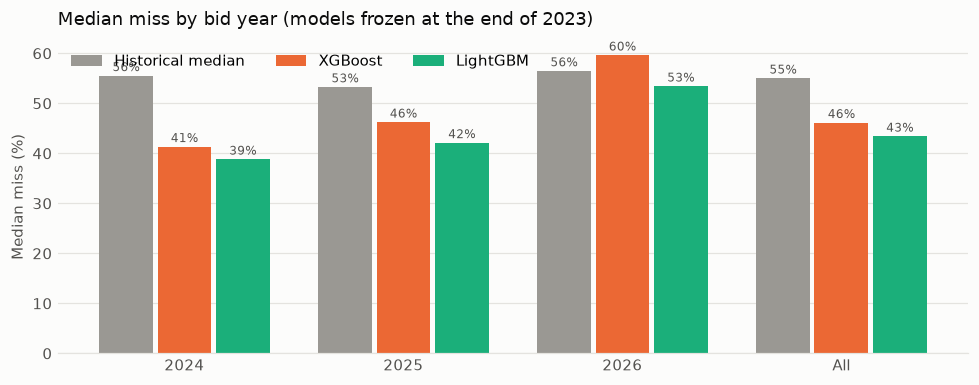

In [5]:
fig = s.chart_by_year(
    s.baseline_by_year(scores),
    ["trailing_median", "xgboost", "lightgbm"],
    "Median miss by bid year (models frozen at the end of 2023)",
    "Median miss (%)",
)
s.save(fig, "mdape_by_year", s.S10)
plt.show()

## What the models rely on

Each bar is the share of a model's learning that came from one fact. Both models mostly learn *which item it is*, *what it usually costs* and *how much of it there is*. Contract size and type of work add little.

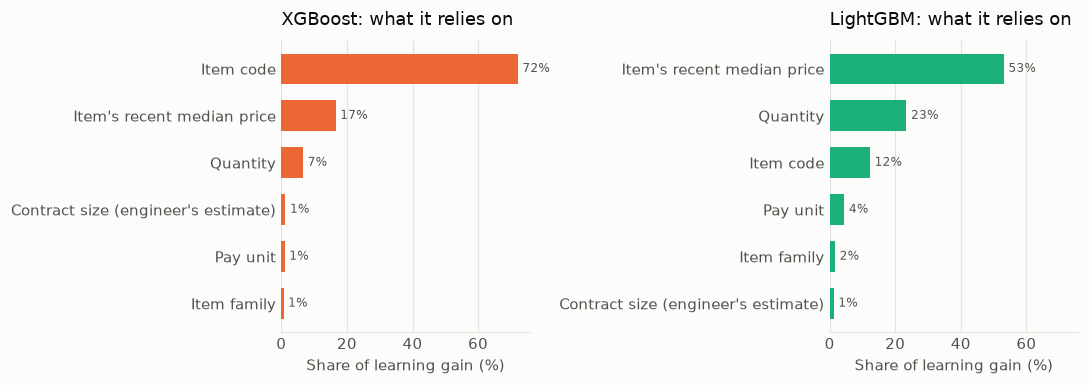

In [6]:
fig = s.chart_feature_importance(s.feature_importance())
s.save(fig, "feature_importance", s.S10)
plt.show()

## Tuning and speed

Thirty settings per model were tried on 2023 bids. The table shows the chosen setting's score, how much it moved across random seeds (the reason for averaging three fits), and how fast the models are. Pricing every test item takes a fraction of a second.

In [7]:
s.tuning_summary()

,,XGBoost,LightGBM
0,Median miss on 2023 bids (one fit),39.6%,40.8%
1,Range over six single seeds,39.6% to 40.9%,40.8% to 43.4%
2,Three-seed average (used),40.1%,41.2%
3,Trees,457,212
4,Fit time (three fits),1.4 s,10.7 s
5,"Time to price 4,507 test items",16 ms,46 ms


## Save and next

This adds the charts above to `outputs/10_baselines/` and lists them in its README. To recompute: `uv run python -m bidlens.pricing.compare`, then `uv run python -m bidlens.pricing.baseline` (about 2 minutes).

**Next:** *04 Kumo Tabular*, a pretrained model scored on the same test.

In [8]:
s.note_in_readme(s.S10, "03_xgboost_baseline.ipynb")
sorted(p.name for p in s.S10.glob("nb_*.png"))

['nb_feature_importance.png', 'nb_mdape_by_family.png', 'nb_mdape_by_year.png']